<a href="https://colab.research.google.com/github/Fauzi455/PCVK26_12_M-Fauzi-R/blob/main/Week9_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRAKTIKUM MORFOLOGI

1. Import folder yang ada di Drive Anda dengan cara sebagai berikut.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu ke-9 berikut.

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

3. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:

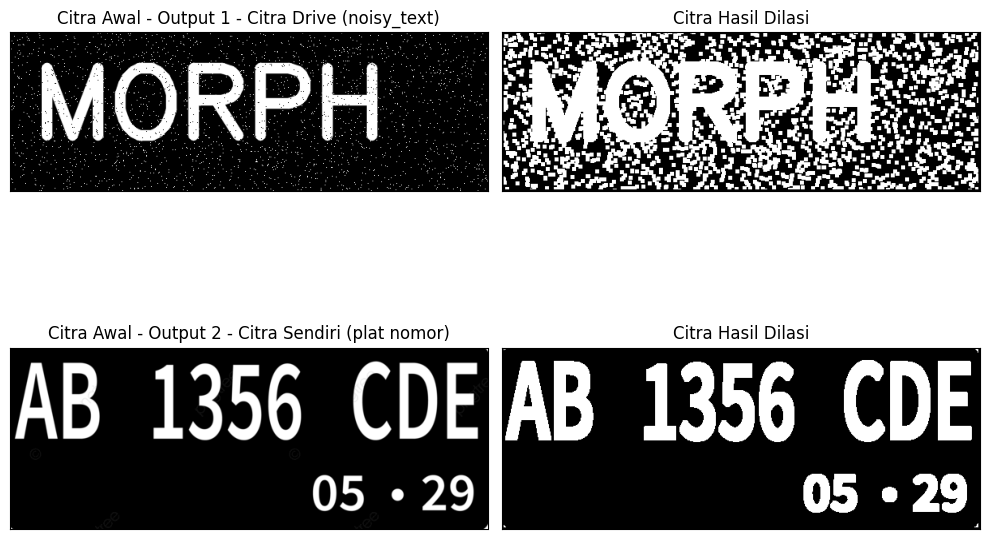

In [10]:
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

w = 5

# Buat satu figur besar untuk menampung grid 2x2
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:  # Membatasi hanya untuk 2 output citra
        break

    # Membaca gambar langsung dari path lengkap
    img_d = cv2.imread(berkas, 0)

    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, w)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:

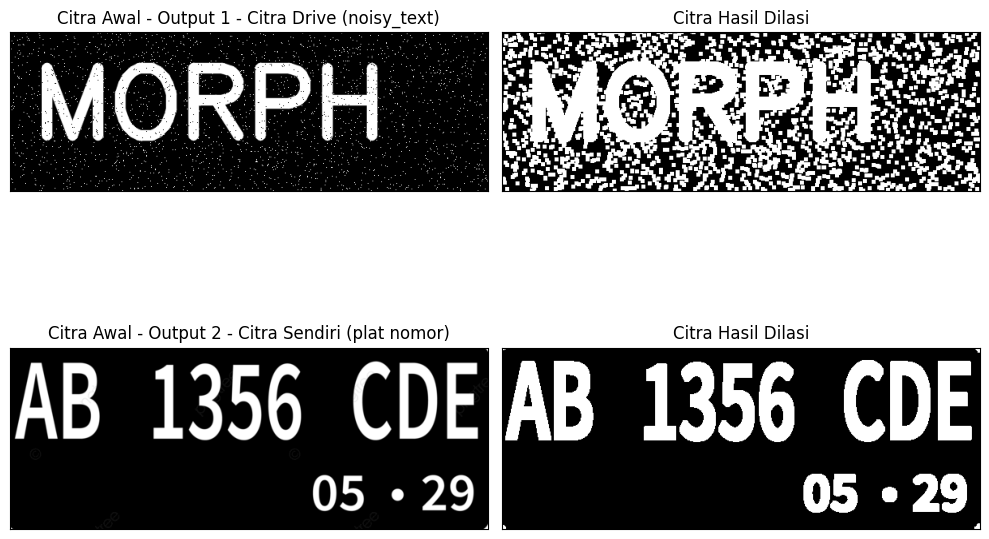

In [11]:
# Daftar path citra
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Gunakan tipe data np.uint8 agar kompatibel dengan operasi morfologi OpenCV
kernel = np.ones((5, 5), dtype=np.uint8)

# Menampilkan grid 2x2
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_d = cv2.imread(berkas, 0)

    if img_d is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Thresholding
    ret, thresh = cv2.threshold(img_d, 125, 255, cv2.THRESH_BINARY)

    # Proses Dilasi menggunakan OpenCV
    imgD = cv2.dilate(thresh, kernel, iterations=1)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:

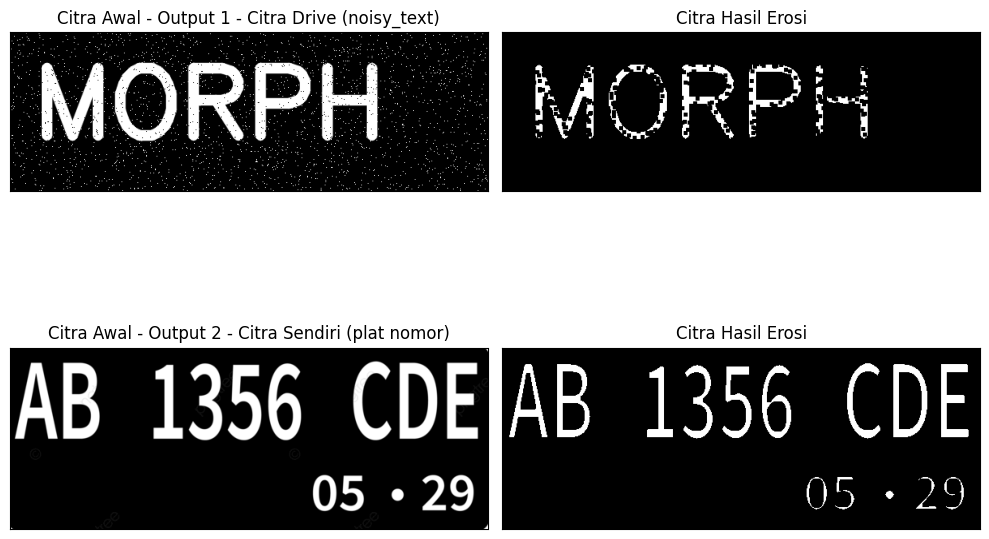

In [14]:
# Fungsi Erosi Manual tanpa library morphology OpenCV
def erosi_citra(F, k):
    # Size image
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Generate structuring element erosi (SE) berbentuk square k x k
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

k = 5  # Ukuran structuring element 5x5

plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_e = cv2.imread(berkas, 0)
    if img_e is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Thresholding citra
    ret, thresh = cv2.threshold(img_e, 125, 255, cv2.THRESH_BINARY)

    # Menjalankan fungsi erosi manual
    imgE = erosi_citra(thresh, k)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk square 5 x 5 dengan menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:

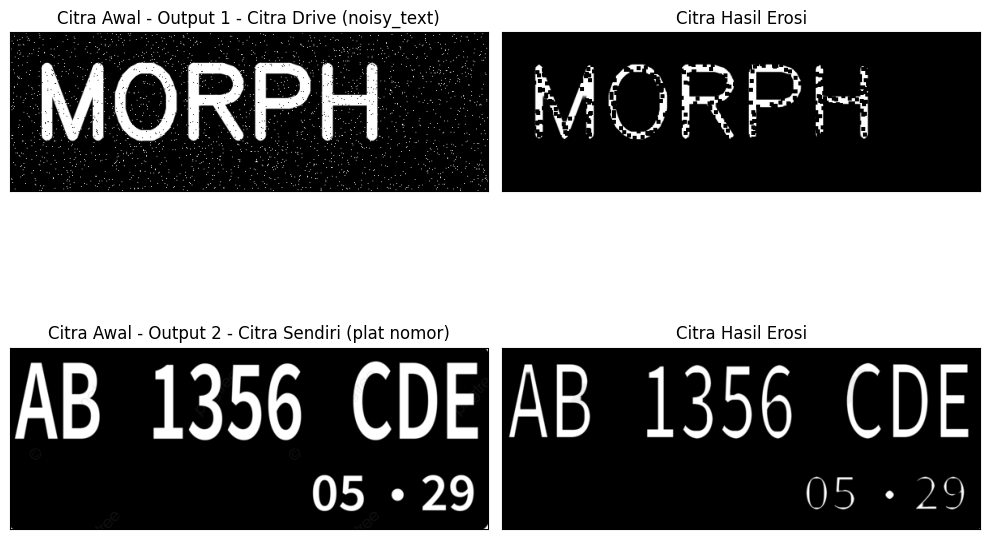

In [19]:
# Daftar citra yang akan diproses
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Kernel / Structuring Element square 5x5 bertipe uint8 sesuai modul
kernel = np.ones((5, 5), np.uint8)

# Siapkan figur untuk grid 2x2
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # Membaca citra (grayscale)
    img = cv2.imread(berkas, 0)

    # Operasi erosi menggunakan library OpenCV
    erosion = cv2.erode(img, kernel, iterations=1)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(erosion, cmap='gray')
    plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

7. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV, **sehingga** menghasilkan tampilan seperti di bawah ini:

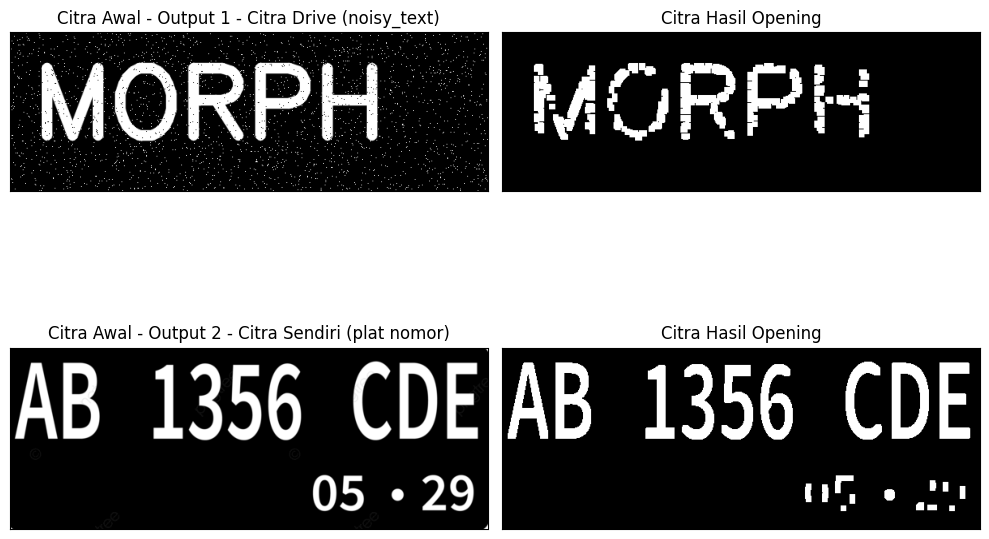

In [22]:
# Fungsi Erosi Manual
def erosi_citra(F, k):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

# Fungsi Dilasi Manual
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

k = 7

# Satu figure untuk menampung kedua pasang citra (grid 2x2)
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_o = cv2.imread(berkas, 0)
    if img_o is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Thresholding sesuai kode yang diminta
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

    # Operasi Opening: dilasi dari hasil erosi
    imgO = dilasi_citra(erosi_citra(thresho, k), k)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Opening
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

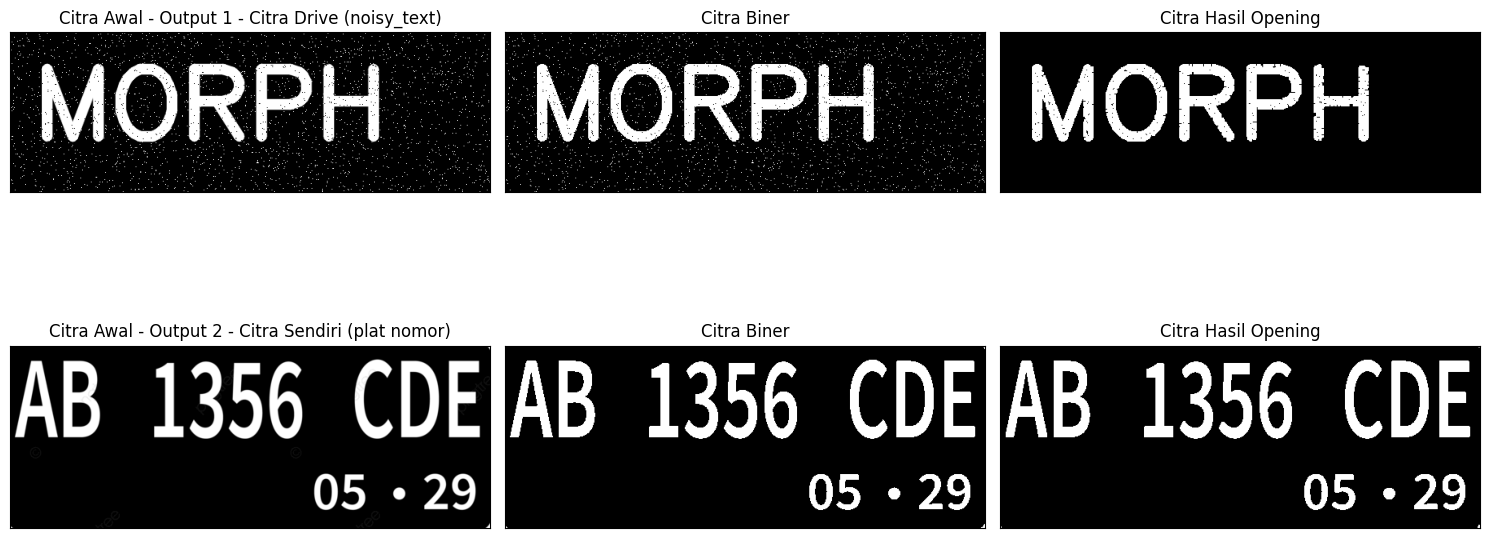

In [23]:
#Operasi Opening Menggunakan Library Morphology
# Daftar citra
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Kernel / Structuring Element square 3x3
kernel = np.ones((3, 3), np.uint8)

# Siapkan figur untuk grid 2 baris x 3 kolom
plt.figure(figsize=(15, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # Membaca citra grayscale
    img = cv2.imread(berkas, 0)
    if img is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Thresholding untuk menghasilkan citra biner
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

    # Operasi Opening menggunakan library OpenCV
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    # Kolom 1: Citra Awal
    plt.subplot(2, 3, idx * 3 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Kolom 2: Citra Biner
    plt.subplot(2, 3, idx * 3 + 2)
    plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner')
    plt.xticks([]), plt.yticks([])

    # Kolom 3: Citra Hasil Opening
    plt.subplot(2, 3, idx * 3 + 3)
    plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

8. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:

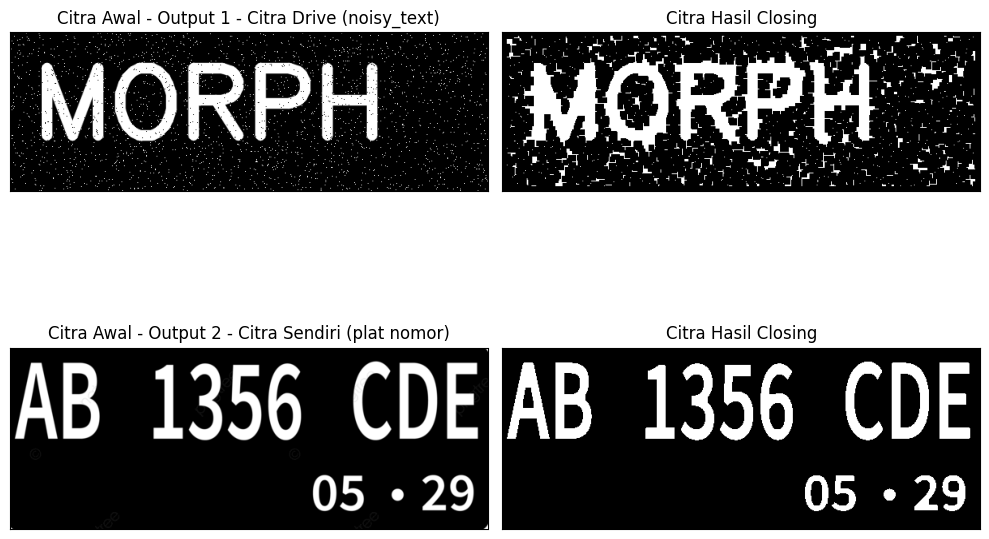

In [24]:
# Fungsi Dilasi Manual
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Fungsi Erosi Manual
def erosi_citra(F, k):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

# Daftar citra
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Nilai k sesuai kode modul (k=7) atau soal (k=3)
k = 7

plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_c = cv2.imread(berkas, 0)
    if img_c is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Thresholding sesuai kode modul
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

    # Operasi Closing: Erosi dari hasil Dilasi
    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_c, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Closing
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgC, cmap='gray')
    plt.title('Citra Hasil Closing')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

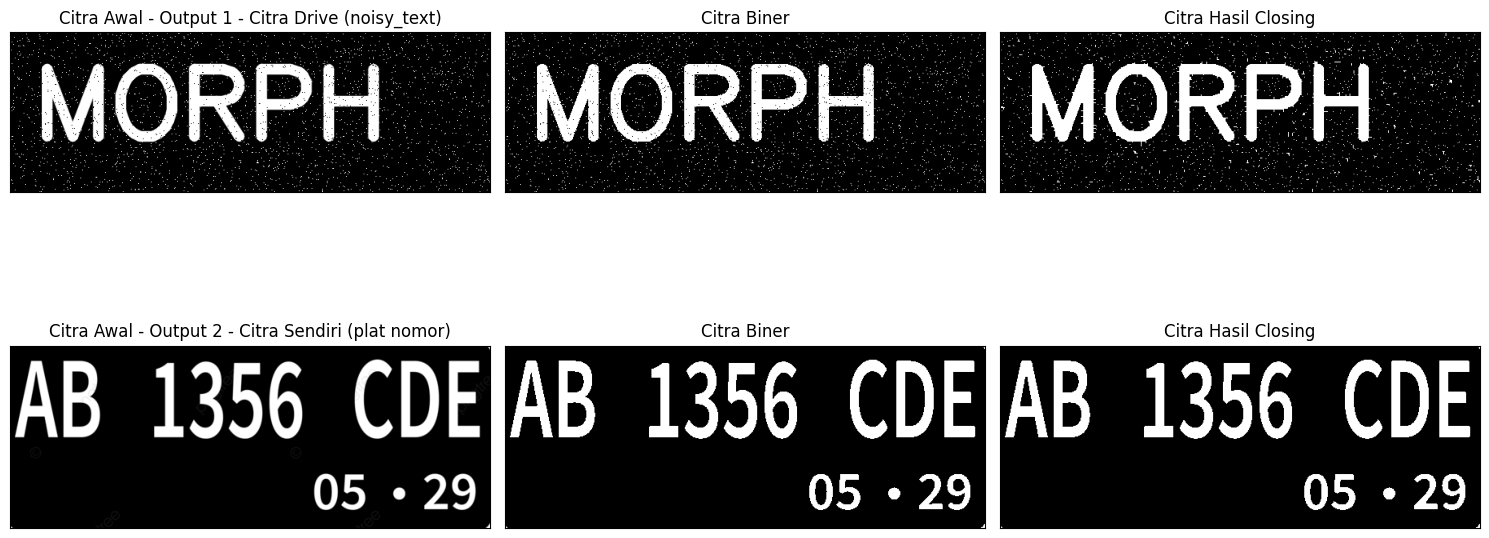

In [25]:
#operasi closing dengan library morphology
# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Kernel / Structuring Element square 3x3 sesuai modul
kernel = np.ones((3, 3), np.uint8)

# Siapkan figur untuk grid 2 baris x 3 kolom
plt.figure(figsize=(15, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # 1. Membaca citra grayscale
    img = cv2.imread(berkas, 0)
    if img is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # 2. Thresholding untuk menghasilkan citra biner
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

    # 3. Operasi Closing menggunakan library OpenCV
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # Kolom 1: Citra Awal
    plt.subplot(2, 3, idx * 3 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Kolom 2: Citra Biner
    plt.subplot(2, 3, idx * 3 + 2)
    plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner')
    plt.xticks([]), plt.yticks([])

    # Kolom 3: Citra Hasil Closing
    plt.subplot(2, 3, idx * 3 + 3)
    plt.imshow(closs, cmap='gray')
    plt.title('Citra Hasil Closing')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Cross 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:

SED = Cross 3


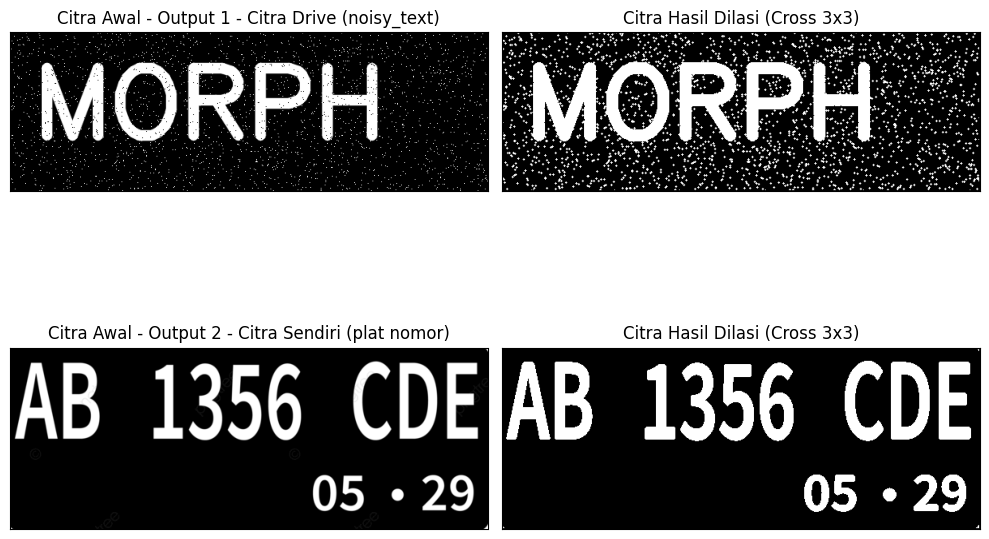

SED = Cross 5


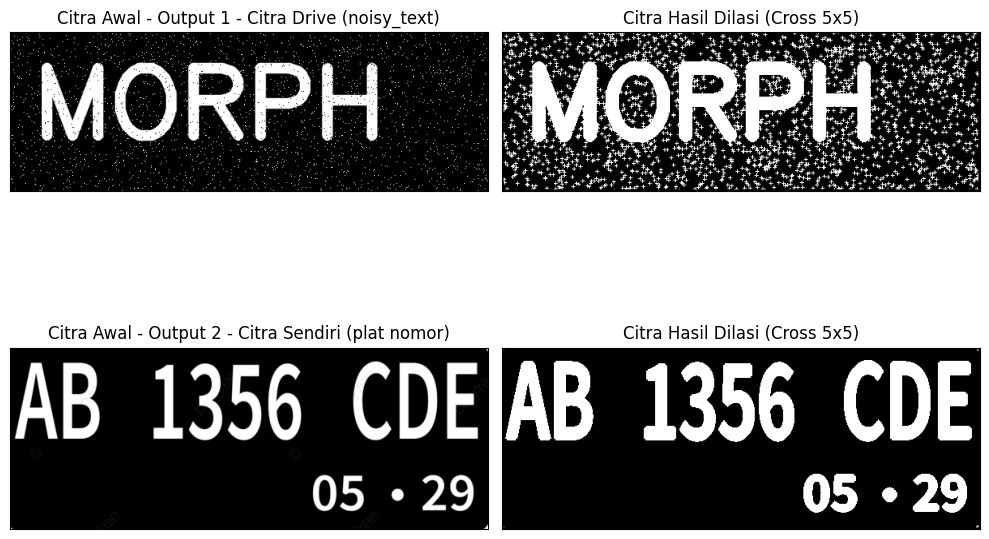

In [27]:
# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Definisi Structuring Element (SE) Cross 3x3 dan 5x5
sed_cross_3 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

sed_cross_5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)

# Fungsi dilasi manual dengan parameter structuring element (SED)
def dilasi_citra(F, SED, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# ============================================================
# 1. TAMPILAN DILASI CROSS 3x3
# ============================================================
print('SED = Cross 3')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_d = cv2.imread(berkas, 0)
    if img_d is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, sed_cross_3, w=3)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi (Cross 3x3)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

# ============================================================
# 2. TAMPILAN DILASI CROSS 5x5
# ============================================================
print('SED = Cross 5')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_d = cv2.imread(berkas, 0)
    if img_d is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, sed_cross_5, w=5)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi (Cross 5x5)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

10. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Circular 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:

SED = Circle 3


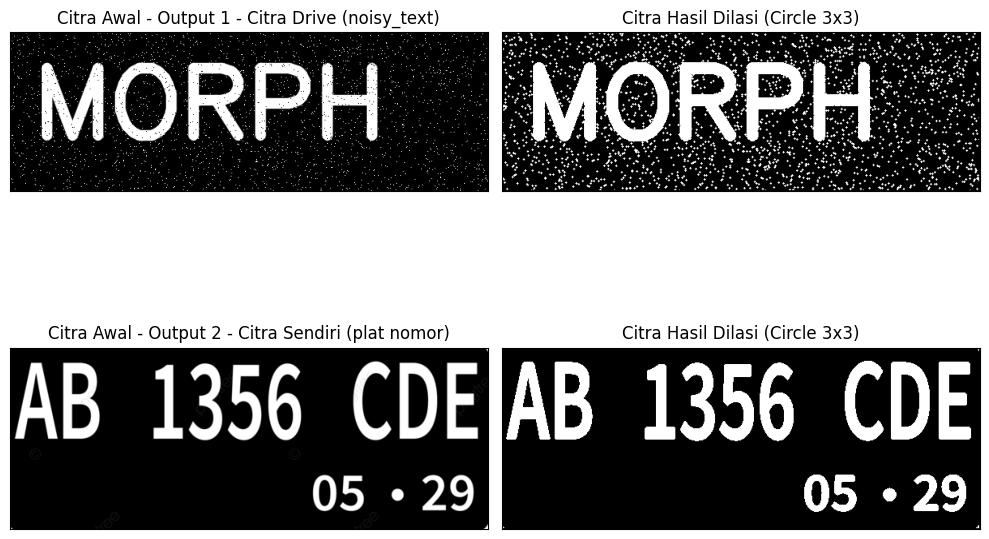

SED = Circle 5


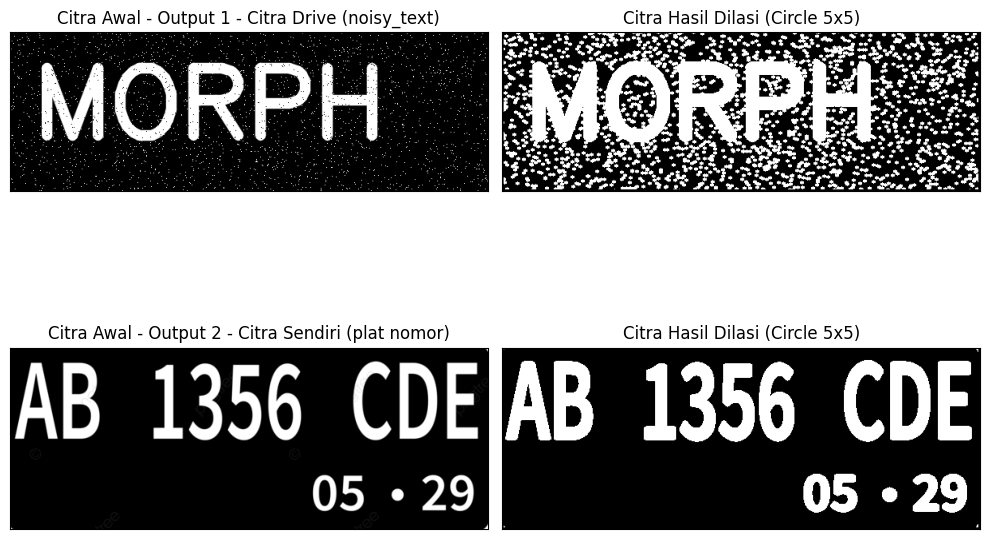

In [28]:
# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Fungsi dilasi manual dengan structuring element circular
def dilasi_citra(F, w):
    # Size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structuring element dilasi (SED) circular/ellipse
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# ============================================================
# 1. DILASI CIRCULAR 3x3
# ============================================================
print('SED = Circle 3')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_d = cv2.imread(berkas, 0)
    if img_d is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 3
    imgD = dilasi_citra(thresh, w)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi (Circle 3x3)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

# ============================================================
# 2. DILASI CIRCULAR 5x5
# ============================================================
print('SED = Circle 5')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_d = cv2.imread(berkas, 0)
    if img_d is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 5
    imgD = dilasi_citra(thresh, w)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Dilasi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi (Circle 5x5)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

11. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7, sehingga menghasilkan tampilan seperti di bawah ini:

SE = Rectangle 3x5


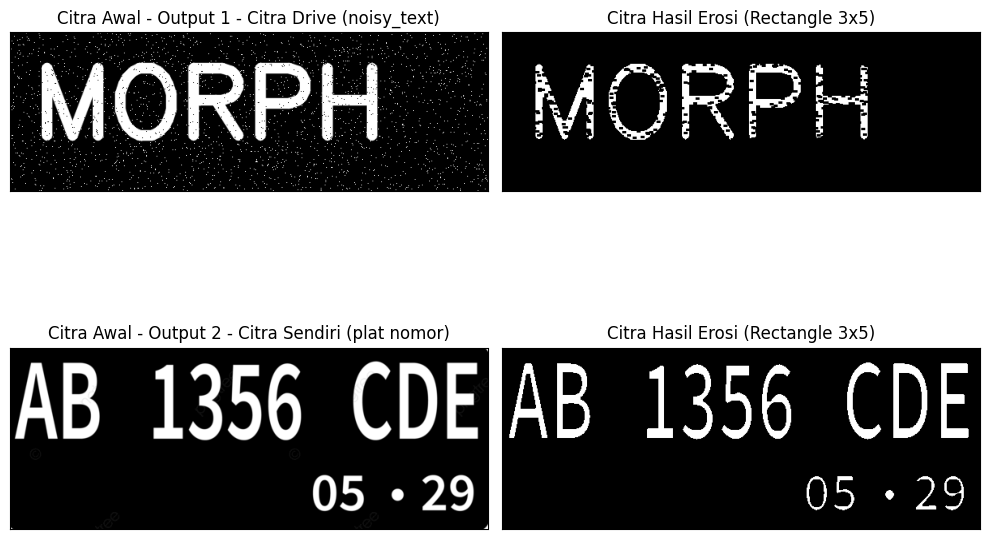

SE = Rectangle 5x7


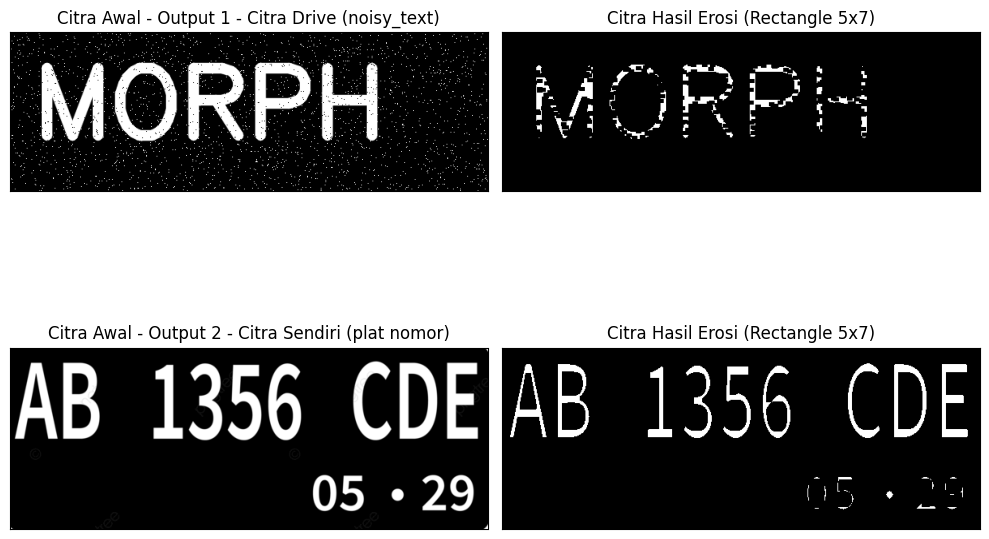

In [29]:
# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Fungsi erosi manual dengan structuring element persegi panjang (Rectangle)
def erosi_citra(F, p, l):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE) persegi panjang
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# ============================================================
# 1. EROSI RECTANGLE 3x5
# ============================================================
print('SE = Rectangle 3x5')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_e = cv2.imread(berkas, 0)
    if img_e is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p = 5
    l = 3
    imgE = erosi_citra(thresh1, p, l)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi (Rectangle 3x5)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

# ============================================================
# 2. EROSI RECTANGLE 5x7
# ============================================================
print('SE = Rectangle 5x7')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    img_e = cv2.imread(berkas, 0)
    if img_e is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p = 7
    l = 5
    imgE = erosi_citra(thresh1, p, l)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi (Rectangle 5x7)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

12. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk Line Vertikal 3 dan 5, sehingga menghasilkan tampilan seperti di bawah ini: (Gunakan gambar j.png)

SE = Line Vertikal 3


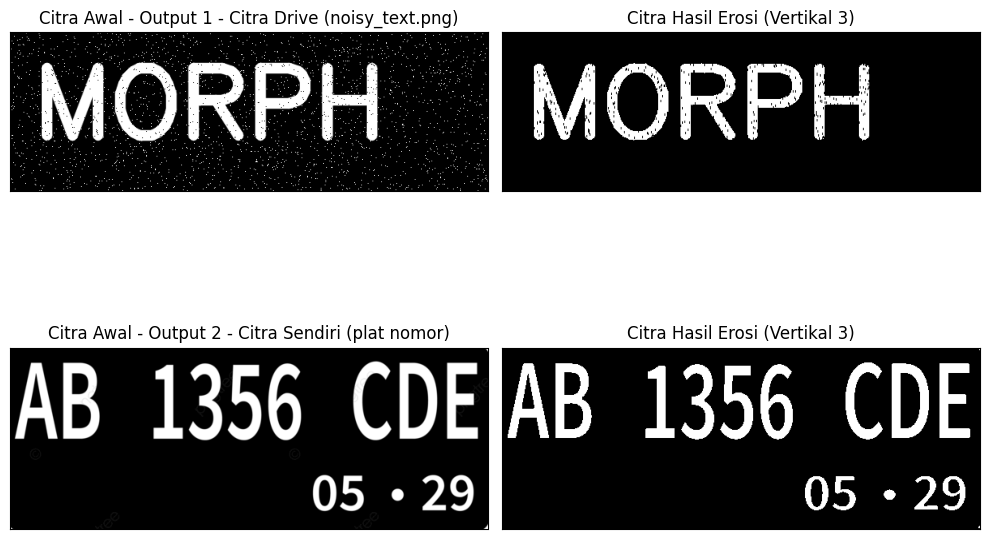

SE = Line Vertikal 5


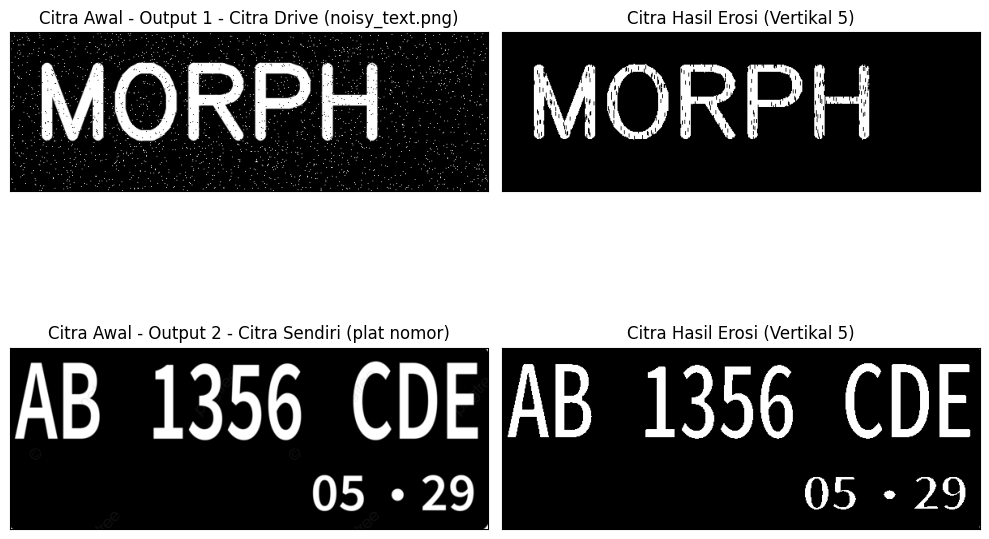

In [40]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Pastikan path mengarah ke file noisy_text.png dan plat.png yang tepat
daftar_citra = [
    ('Output 1 - Citra Drive (noisy_text.png)', '/content/drive/MyDrive/PCVK/Images/244107020067/noisy_text.png'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Fungsi erosi manual dengan SE Line Vertikal
def erosi_citra(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(n):
            temp = F[i - constant:i + constant + 1, j]
            temp = temp.reshape(k, 1)
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

# ============================================================
# 1. EROSI LINE VERTIKAL 3
# ============================================================
print('SE = Line Vertikal 3')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # Membaca citra yang sesuai pada setiap iterasi
    img_e = cv2.imread(berkas, 0)
    if img_e is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k = 3
    imgE = erosi_citra(thresh1, k)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi (Vertikal 3)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

# ============================================================
# 2. EROSI LINE VERTIKAL 5
# ============================================================
print('SE = Line Vertikal 5')
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # Membaca citra yang sesuai pada setiap iterasi
    img_e = cv2.imread(berkas, 0)
    if img_e is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k = 5
    imgE = erosi_citra(thresh1, k)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Erosi
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi (Vertikal 5)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

13. Buatlah program transformasi Top-hat dengan structuring element 3 × 3, lalu tampilkan citra asal dan hasilnya secara berdampingan.https://colab.research.google.com/

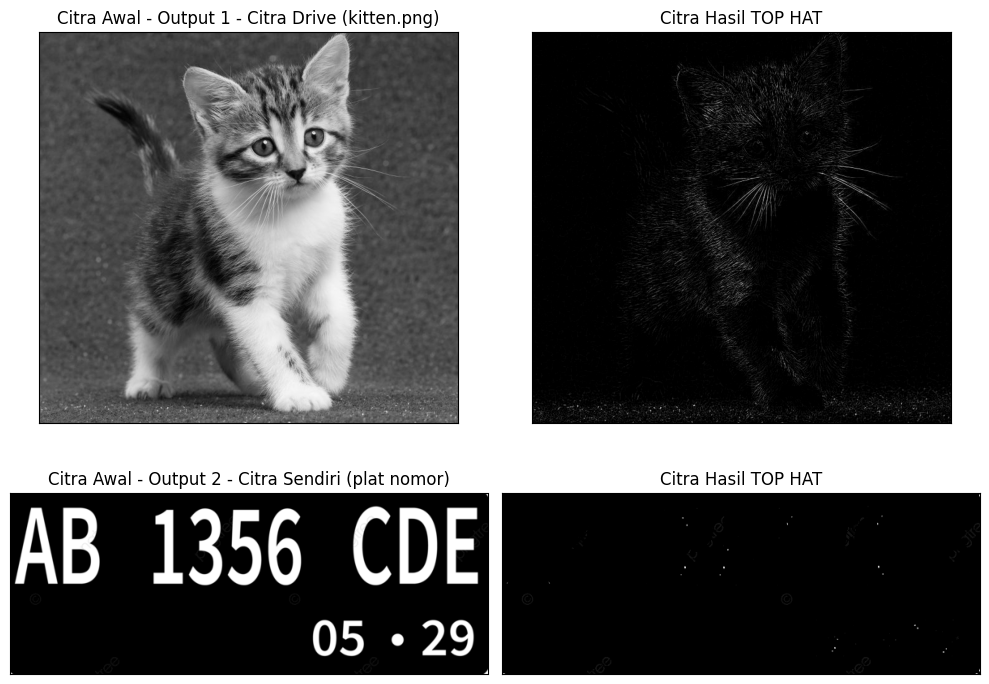

In [46]:
# Daftar citra: Citra 1 (kitten) dan Citra 2 (citra sendiri)
daftar_citra = [
    ('Output 1 - Citra Drive (kitten.png)', '/content/drive/MyDrive/PCVK/Images/244107020067/kitten01 (1).jpg'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# 1. Mendapatkan kernel untuk Top-Hat (Structuring Element 3x3)
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Siapkan figur untuk grid 2x2
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # 2. Membaca citra dan konversi ke grayscale
    img_bgr = cv2.imread(berkas)
    if img_bgr is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 3. Menerapkan operasi Top-Hat
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Top-Hat
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(tophat_img, cmap='gray')
    plt.title('Citra Hasil TOP HAT')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

14. Buatlah program transformasi Black-hat dengan structuring element 3 × 3. Ingat, Black-hat adalah hasil closing dikurangi citra asal.https://colab.research.google.com/

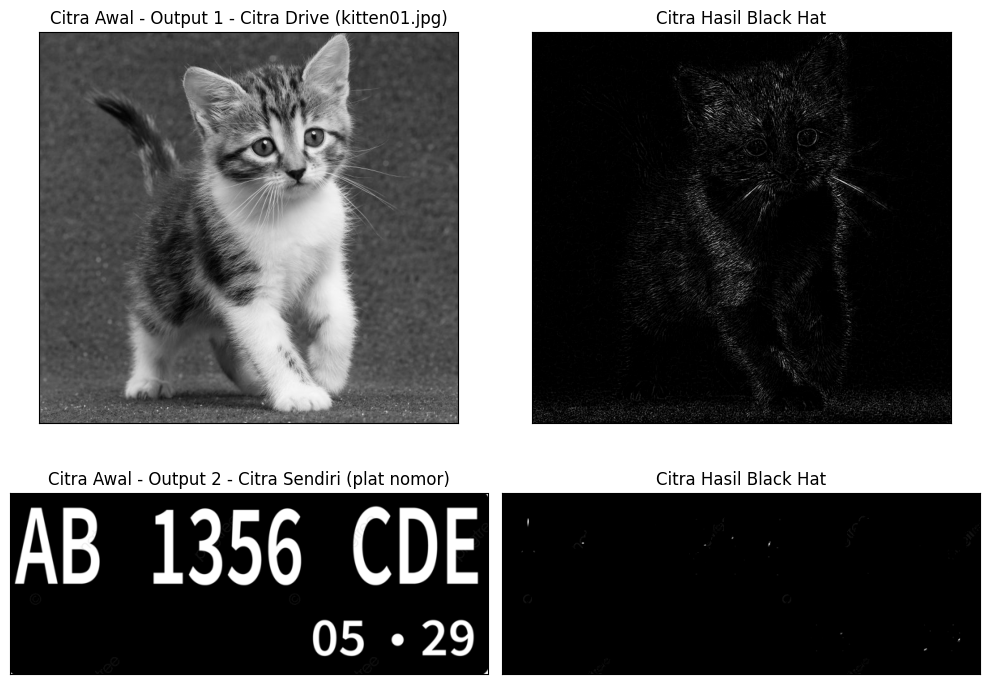

In [49]:
# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (kitten01.jpg)', '/content/drive/MyDrive/PCVK/Images/244107020067/kitten01 (1).jpg'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Definisi kernel structuring element (3x3 sesuai deskripsi soal nomor 14)
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Jika ingin mengikuti persis baris kode di dalam modul yang menggunakan (13, 5):
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

# Inisialisasi canvas grid 2x2
plt.figure(figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # Membaca citra
    img_bgr = cv2.imread(berkas)
    if img_bgr is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # Konversi ke grayscale
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Menerapkan operasi Black-Hat
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

    # Subplot kolom kiri: Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Citra Hasil Black Hat
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(blackhat, cmap='gray')
    plt.title('Citra Hasil Black Hat')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

15. Buatlah program skeleton pada citra biner, lalu tampilkan citra biner dan rangkanya secara berdampingan.https://colab.research.google.com/

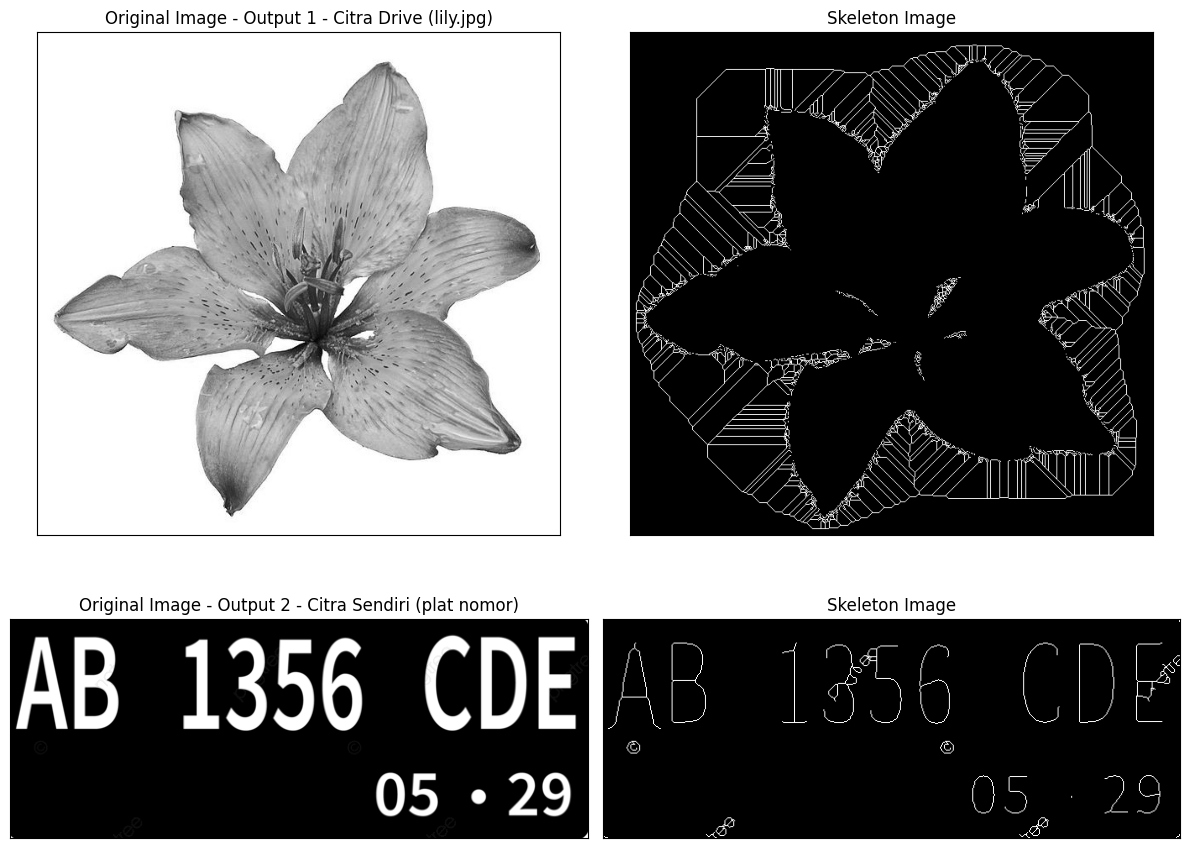

In [52]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from skimage import filters
from skimage.morphology import skeletonize

# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (lily.jpg)', '/content/drive/MyDrive/PCVK/Images/244107020067/lily.jpg'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Siapkan figur untuk grid 2 baris x 2 kolom
plt.figure(figsize=(12, 10))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # 1. Membaca citra grayscale
    img = cv.imread(berkas, 0)
    if img is None:
        print(f"Error: Berkas tidak ditemukan di {berkas}")
        continue

    # 2. Binerisasi menggunakan threshold_triangle
    binary = img > filters.threshold_triangle(img)

    # 3. Konversi nilai True/False menjadi 1 dan 0
    binary_cp = binary.copy().astype(np.uint8)
    binary_cp[binary_cp == True] = 1
    binary_cp[binary_cp == False] = 0

    # 4. Operasi skeletonize
    skeleton = skeletonize(binary_cp)

    # Subplot kolom kiri: Original Image / Citra Awal
    plt.subplot(2, 2, idx * 2 + 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image - ' + judul)
    plt.xticks([]), plt.yticks([])

    # Subplot kolom kanan: Skeleton Image
    plt.subplot(2, 2, idx * 2 + 2)
    plt.imshow(skeleton, cmap='gray')
    plt.title('Skeleton Image')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.savefig("binary_and_bin_skeleton.png")
plt.show()

16. Buatlah program skeleton pada citra hasil inversi, lalu bandingkan hasilnya dengan langkah sebelumnya.https://colab.research.google.com/

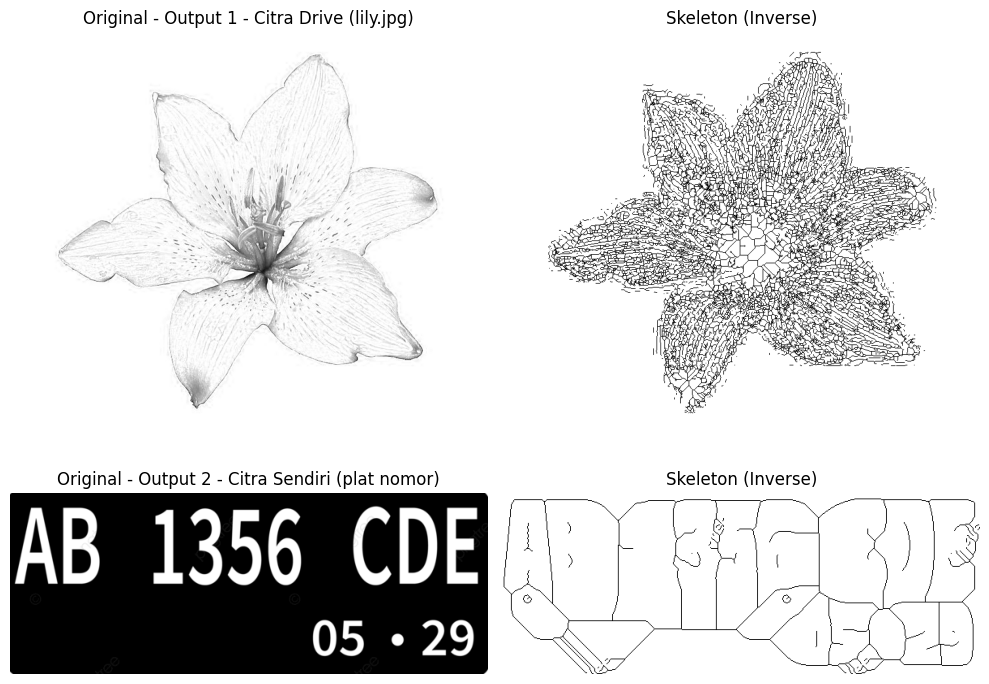

In [54]:
from skimage import io, filters
from skimage.morphology import skeletonize
import matplotlib.pyplot as plt

# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (lily.jpg)', '/content/drive/MyDrive/PCVK/Images/244107020067/lily.jpg'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Siapkan figur untuk grid 2 baris x 2 kolom
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # 1. Membaca citra (mengambil channel pertama / grayscale)
    try:
        raw_img = io.imread(berkas)
        if raw_img.ndim == 3:
            img = raw_img[..., 0]
        else:
            img = raw_img
    except Exception as e:
        print(f"Error membaca berkas {berkas}: {e}")
        continue

    # 2. Inversi threshold: bagian hitam dijadikan True (menggunakan tanda <)
    binary = img < filters.threshold_triangle(img)

    # 3. Skeletonize pada citra biner inversi
    skeleton = skeletonize(binary)

    # Kolom kiri: Citra Awal / Original
    ax[idx, 0].imshow(img, cmap='gray')
    ax[idx, 0].set_title('Original - ' + judul)
    ax[idx, 0].axis('off')

    # Kolom kanan: Hasil Skeleton Inversi (menggunakan colormap gray_r)
    ax[idx, 1].imshow(skeleton, cmap='gray_r')
    ax[idx, 1].set_title('Skeleton (Inverse)')
    ax[idx, 1].axis('off')

plt.tight_layout()
plt.show()

17. Buatlah program thinning memakai morphology.thin(), lalu bandingkan hasilnya dengan skeleton pada langkah 15 https://colab.research.google.com/

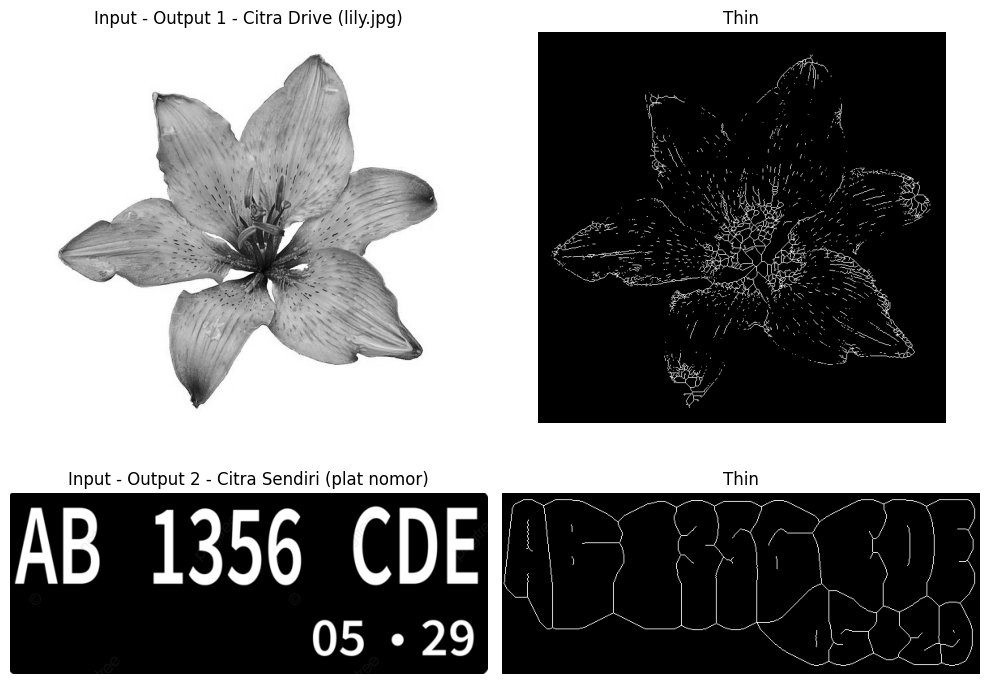

In [55]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

# Daftar citra yang diproses
daftar_citra = [
    ('Output 1 - Citra Drive (lily.jpg)', '/content/drive/MyDrive/PCVK/Images/244107020067/lily.jpg'),
    ('Output 2 - Citra Sendiri (plat nomor)', '/content/drive/MyDrive/PCVK/Images/244107020067/plat.png')
]

# Siapkan kanvas grid 2 baris x 2 kolom
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

for idx, (judul, berkas) in enumerate(daftar_citra):
    if idx >= 2:
        break

    # 1. Membaca citra dan konversi ke float grayscale
    try:
        raw_img = io.imread(berkas)
        if raw_img.ndim == 3:
            # Jika citra memiliki 4 channel (RGBA), potong channel Alpha
            if raw_img.shape[-1] == 4:
                raw_img = raw_img[..., :3]
            image = img_as_float(color.rgb2gray(raw_img))
        else:
            image = img_as_float(raw_img)
    except Exception as e:
        print(f"Error membaca berkas {berkas}: {e}")
        continue

    # 2. Binerisasi citra (image < 0.5)
    image_binary = image < 0.5

    # 3. Operasi Thinning dan Skeletonize
    out_skeletonize = morphology.skeletonize(image_binary)
    out_thin = morphology.thin(image_binary)

    # Kolom kiri: Citra Input
    ax[idx, 0].imshow(image, cmap='gray')
    ax[idx, 0].set_title('Input - ' + judul)
    ax[idx, 0].axis('off')

    # Kolom kanan: Citra Hasil Thinning
    ax[idx, 1].imshow(out_thin, cmap='gray')
    ax[idx, 1].set_title('Thin')
    ax[idx, 1].axis('off')

plt.tight_layout()
plt.savefig('/tmp/char_out.png')
plt.show()